# 03 · Fenología y variables satelitales — Reto AgroCebada 2026

## Qué hace este cuaderno
El cuaderno 02 dejó a cada parcela con una curva diaria limpia por índice. Un modelo no puede aprender directamente de una curva: necesita un conjunto fijo de números por parcela. Este cuaderno lee la temporada 2025 de cada parcela a partir de su curva (cuándo emergió el cultivo, cuándo alcanzó su pico, cuándo se secó, qué tan verde llegó a estar, qué tan rápido creció) y usa esas **fechas propias de cada parcela** para resumir todos los demás índices en las etapas del ciclo del propio cultivo. El resultado es **una fila por parcela** con unos cientos de variables documentadas: la parte satelital de la entrada del modelo.

## Por qué fechas de la curva de cada parcela (y no meses del calendario)
Dos parcelas sembradas con tres semanas de diferencia están en etapas distintas el mismo día del calendario. Promediar el estrés hídrico de «agosto» mezcla la floración de una parcela con el amacollamiento de otra. Promediarlo en «los 30 días alrededor de la mitad de la temporada de *esta* parcela» compara etapas equivalentes. La auditoría mostró diferencias reales de calendario entre municipios y parcelas, así que aquí importa.

## Pasos
| Paso | Qué | Salida |
|---|---|---|
| A | Detectar la **temporada principal** de cada parcela en el NDVI de Planet (y, como contraste, en el NDVI de Sentinel-2) | fechas: inicio, pico, centro y fin; forma: pico, amplitud, tasas, integrales |
| B | Verificar que las fechas tengan sentido agronómico y que los dos satélites coincidan | figuras de control y verificaciones |
| C | Resumir cada índice de Planet, Sentinel-2 y Landsat en **ventanas de etapa del cultivo** definidas por las fechas de cada parcela | medias y máximos por ventana |
| D | **Uniformidad dentro de la parcela** a mitad de temporada, con los estadísticos espaciales por imagen de Planet | variables de uniformidad |
| E | **Historial 2022–2024** con Sentinel-2: la productividad habitual de la parcela y cómo se compara 2025 | variables de historial y anomalías |
| F | Integrar, depurar (eliminar variables constantes), documentar cada variable en un catálogo y una primera mirada descriptiva al rendimiento | `features/sat_features.parquet`, catálogo, reporte |

## Reglas
- **Ninguna variable se construye con el rendimiento.** Las parcelas de entrenamiento y de predicción se procesan igual. El rendimiento solo aparece en la última celda, puramente descriptiva (solo parcelas de entrenamiento); con ella no se selecciona nada: la selección ocurre dentro de los pliegues de validación cruzada en los cuadernos 06 y 07.
- **Los sensores se mantienen separados.** Planet, Sentinel-2 y Landsat producen cada uno sus propias variables (el NDVI de Sentinel-2 es ~0.08 menor que el de Planet en las mismas parcelas).

## Entradas (de los cuadernos 01–02)
`interim/daily_planet.parquet`, `interim/daily_sentinel2.parquet`, `interim/daily_landsat.parquet`, `interim/sat_obs_qc.parquet`, `interim/plots_attributes.csv`, `interim/labels.parquet` (solo en la última celda).

## Salidas
| Archivo | Contenido |
|---|---|
| `features/sat_features.parquet` | una fila por parcela (197), todas las variables satelitales |
| `features/phenology_dates.parquet` | las fechas de temporada de cada parcela (el cuaderno 04 agrega el clima sobre ellas) |
| `features/feature_catalog.csv` | cada variable: grupo, sensor, índice, ventana, estadístico y descripción |
| `qa/nb03_*.csv`, `qa/figures/nb03_*.png`, `qa/nb03_report.md` | tablas de control, figuras y reporte |

**Tiempo de ejecución:** unos 2–4 minutos.

## 0 · Preparación

In [1]:
# 0.1 · Librerías, Drive y rutas
import os, json, time, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE = Path("/content/drive/MyDrive/AgroCebada") if IN_COLAB else Path(os.environ.get("AGC_BASE", "AgroCebada"))
INTERIM, FEATURES, QA = BASE / "interim", BASE / "features", BASE / "qa"
FIG = QA / "figures"
for d in [FEATURES, FIG]:
    d.mkdir(parents=True, exist_ok=True)
for f in ["daily_planet.parquet", "daily_sentinel2.parquet", "daily_landsat.parquet", "sat_obs_qc.parquet", "plots_attributes.csv"]:
    assert (INTERIM / f).exists(), f"Falta {INTERIM / f}: ejecuta primero los cuadernos 01 y 02."

SEED = 42
RNG = np.random.default_rng(SEED)
if "display" not in globals():
    display = print
print(f"BASE = {BASE} | Colab: {IN_COLAB} | pandas {pd.__version__}")

Mounted at /content/drive
BASE = /content/drive/MyDrive/AgroCebada | Colab: True | pandas 2.2.3


In [2]:
# 0.2 · Configuración fija (decidida antes de ver cualquier resultado)
YEAR = 2025
SEASON_SEARCH = (f"{YEAR}-04-01", f"{YEAR}-12-31")   # dónde puede estar una temporada 2025 (ciclo abril–octubre, senescencia hasta nov–dic)
PHENO = dict(min_prom_frac=0.15,   # una joroba cuenta como pico si sube ≥ 15 % del rango del año sobre su entorno
             min_amp=0.10,         # una temporada necesita al menos 0.10 de NDVI entre suelo desnudo y pico
             split_depth=0.35,     # dos picos son temporadas separadas solo si el valle entre ellos baja ≥ 35 % del camino de regreso al suelo desnudo
             thr=0.20)             # inicio / fin de temporada = 20 % de la amplitud (método estándar de umbral de amplitud)
MID_HALF = 15                      # ventana de mitad de temporada = centro de la temporada ± 15 días
POST_DAYS = 30                     # ventana poscosecha = 30 días después del fin de temporada (residuo del cultivo)
UNIF_HALF = 20                     # uniformidad: imágenes de Planet a ± 20 días del centro de la temporada
MAX_GAP_OK = {"Planet": 30, "Sentinel-2": 45}   # hueco máximo en temporada antes de marcar una parcela como de baja confianza
RESIDUE_IDX = ["crc", "mcrc", "ndti", "sti", "ndsvi"]

COLORS = {"Planet": "#2a78d6", "Sentinel-2": "#eb6834", "Landsat": "#1baf7a"}
MUNI_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
GREY, RED, INK = "#9a9a94", "#e34948", "#2b2b28"
STAGE_COLORS = {"early": "#cde2fb", "mid": "#86b6ef", "late": "#f6d7c3", "post": "#ececE6"}
# meses en español para los ejes de las figuras
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
FMT_MES = matplotlib.ticker.FuncFormatter(lambda x, _: MESES[matplotlib.dates.num2date(x).month - 1])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#b8b7ae", "axes.labelcolor": INK, "xtick.color": "#6b6b66",
                     "ytick.color": "#6b6b66", "font.size": 9, "legend.frameon": False})

CHECKS = []
def check(name, ok, detail="", warn_only=True, info=False):
    status = "INFO" if info else ("PASS" if ok else ("WARN" if warn_only else "FAIL"))
    rec = {"check": name, "status": status, "detail": str(detail)}
    for j, r in enumerate(CHECKS):
        if r["check"] == name:
            CHECKS[j] = rec
            break
    else:
        CHECKS.append(rec)
    print(f"[{status}] {name}" + (f" — {detail}" if detail != "" else ""))

CATALOG = []
def register(name, group, sensor, index, window, stat, description, unit=""):
    CATALOG.append(dict(feature=name, group=group, sensor=sensor, index=index, window=window,
                        statistic=stat, unit=unit, description=description))

In [3]:
# 0.3 · Carga de datos
daily = {"Planet": pd.read_parquet(INTERIM / "daily_planet.parquet"),
         "Sentinel-2": pd.read_parquet(INTERIM / "daily_sentinel2.parquet"),
         "Landsat": pd.read_parquet(INTERIM / "daily_landsat.parquet")}
qc = pd.read_parquet(INTERIM / "sat_obs_qc.parquet")
plots = pd.read_csv(INTERIM / "plots_attributes.csv")
IDS = plots.ID_POLIGONO.sort_values().tolist()
INDICES = {s: [c for c in d.columns if c not in ("ID_POLIGONO", "date", "gap_days")] for s, d in daily.items()}
for s, d in daily.items():
    print(f"{s:11s} {d.shape}  {d.date.min().date()} → {d.date.max().date()}  indices: {INDICES[s]}")

Planet      (71905, 7)  2025-01-01 → 2025-12-31  indices: ['ndvi', 'evi', 'lai', 'msavi']
Sentinel-2  (287817, 25)  2022-01-01 → 2025-12-31  indices: ['ndvi', 'evi', 'crc', 'mcrc', 'ndsvi', 'srndi', 'mra', 'lai', 'fapar', 'savi', 'ndti', 'sti', 'ndwi', 'endwi', 'msi', 'emsi', 'dswi2', 'dswi3', 'dswi4', 'dswi5', 'nddi', 'enddi']
Landsat     (287817, 4)  2022-01-01 → 2025-12-31  indices: ['vi6t']


## 1 · Paso A: encontrar la temporada principal 2025 de cada parcela

### Cómo se lee la temporada a partir de la curva
Sobre el NDVI diario suavizado de cada parcela entre abril y diciembre de 2025:

1. **Encontrar las jorobas.** Una joroba cuenta como pico si sube al menos 15 % del rango de NDVI del año sobre su entorno («prominencia»), así se ignoran las oscilaciones pequeñas.
2. **Separar temporadas solo en valles profundos.** Cerca de una cuarta parte de las parcelas muestra un rebrote temprano en junio–julio (maleza o rebrote después de las primeras lluvias), una caída brusca (labranza) y luego el cultivo principal. Dos picos se tratan como **temporadas separadas** solo si el valle entre ellos baja al menos 35 % del camino de regreso al suelo desnudo; un valle poco profundo queda dentro de una sola temporada.
3. **La temporada principal es la de mayor área verde** (el área entre la curva y su propio nivel de suelo desnudo). El rebrote temprano se guarda como variables aparte (`early_flush`, su altura y su área; 0 cuando no existe) porque puede decir algo del manejo.
4. **Fechas por el método de umbral de amplitud** (como en el programa TIMESAT): con *base* = nivel de suelo desnudo a cada lado y *amplitud* = pico − base,
   - **SOS** (inicio de temporada) = primer día en que la curva supera base + 20 % de la amplitud; **SOS50** = al superar 50 % (punto medio del reverdecimiento);
   - **POS** = día del pico;
   - **EOS** (fin de temporada) = primer día después del pico en que la curva baja de base + 20 %; **EOS50** = al bajar de 50 %;
   - **centro** = el día que divide en dos mitades el área verde de la temporada. A diferencia del POS no salta entre dos picos casi iguales, así que es el ancla de las ventanas de etapa del cultivo.
5. **Forma**: NDVI máximo, amplitud, tasas máximas de reverdecimiento y senescencia (NDVI por día), integrales del área verde en toda la temporada, antes y después del pico, y *días de meseta* (días a menos de 10 % del pico: cuánto tiempo se mantuvo el dosel en pleno vigor).

**¿Por qué no ajustar una curva doble logística?** Ese modelo clásico supone exactamente un ascenso y un descenso suaves por año. Una cuarta parte de estas parcelas tiene dos jorobas, y forzar una sola curva ubicaría mal la temporada. Las curvas del cuaderno 02 ya son suaves, así que leer las fechas directamente en ellas es más simple y más fiel.

In [4]:
# 1.1 · Función de detección de temporada
def phenology(days, z, win=SEASON_SEARCH, min_prom_frac=0.15, min_amp=0.10, split_depth=0.35, thr=0.20):
    m = (days >= pd.Timestamp(win[0])) & (days <= pd.Timestamp(win[1]))
    d, y = days[m], np.asarray(z, float)[m]
    if len(y) < 60 or not np.isfinite(y).all():
        return {"season_found": False, "n_peaks": 0, "n_seasons": 0}
    gbase = y.min()
    rng = y.max() - gbase
    pk, _ = find_peaks(y, prominence=max(min_prom_frac * rng, 1e-6))
    out = {"n_peaks": len(pk)}
    if len(pk) == 0 or rng < min_amp:
        return {**out, "season_found": False, "n_seasons": 0}
    # separar en temporadas en los valles profundos
    bounds, groups = [0], [[pk[0]]]
    for a, b in zip(pk[:-1], pk[1:]):
        dip = a + int(np.argmin(y[a:b + 1]))
        lower = min(y[a], y[b])
        if (lower - y[dip]) / max(lower - gbase, 1e-6) >= split_depth:
            bounds.append(dip)
            groups.append([b])
        else:
            groups[-1].append(b)
    bounds.append(len(y) - 1)
    seasons = []
    for k, g in enumerate(groups):
        s0, s1 = bounds[k], bounds[k + 1]
        p = g[int(np.argmax(y[g]))]
        lb = s0 + int(np.argmin(y[s0:p + 1]))
        rb = p + int(np.argmin(y[p:s1 + 1]))
        base = max(y[lb], y[rb])
        seasons.append(dict(p=p, lb=lb, rb=rb, area=float(np.clip(y[lb:rb + 1] - base, 0, None).sum())))
    k = int(np.argmax([s["area"] for s in seasons]))
    p, lb, rb = seasons[k]["p"], seasons[k]["lb"], seasons[k]["rb"]
    peak, bl, br = y[p], y[lb], y[rb]
    aL, aR = peak - bl, peak - br
    if min(aL, aR) < min_amp:            # temporada de un solo lado (por ejemplo, todavía verde al final de la ventana)
        aL = aR = max(aL, aR)
    up = lambda lev: lb + int(np.argmax(y[lb:p + 1] >= lev))
    def down(lev):
        seg = y[p:rb + 1]
        hit = seg <= lev
        return p + (int(np.argmax(hit)) if hit.any() else len(seg) - 1)
    sos, sos50 = up(bl + thr * aL), up(bl + 0.5 * aL)
    eos, eos50 = down(br + thr * aR), down(br + 0.5 * aR)
    base = (bl + br) / 2
    above = np.clip(y[sos:eos + 1] - base, 0, None)
    cen = sos + int(np.searchsorted(np.cumsum(above), above.sum() / 2))
    dz = np.gradient(y)
    prev = seasons[k - 1] if k > 0 else None
    out.update(season_found=True, n_seasons=len(seasons),
               sos=d[sos], sos50=d[sos50], pos=d[p], center=d[cen], eos50=d[eos50], eos=d[eos],
               los=int(eos - sos), los50=int(eos50 - sos50),
               peak=float(peak), base_left=float(bl), base_right=float(br), amplitude=float(peak - base),
               greenup_rate=float(dz[sos:p + 1].max()), senescence_rate=float(-dz[p:eos + 1].min()),
               integral_season=float(above.sum()),
               integral_veg=float(np.clip(y[sos:p + 1] - base, 0, None).sum()),
               integral_grainfill=float(np.clip(y[p:eos + 1] - base, 0, None).sum()),
               plateau_days=int((y[sos:eos + 1] >= base + 0.9 * (peak - base)).sum()),
               early_flush=int(prev is not None),
               early_flush_amp=float(y[prev["p"]] - max(y[prev["lb"]], y[prev["rb"]])) if prev else 0.0,
               early_flush_area=float(prev["area"]) if prev else 0.0)
    return out

def season_table(sensor, index="ndvi", win=SEASON_SEARCH):
    rows = []
    for pid, g in daily[sensor].groupby("ID_POLIGONO"):
        r = phenology(pd.DatetimeIndex(g.date), g[index].to_numpy(), win=win, **PHENO)
        r["ID_POLIGONO"] = pid
        rows.append(r)
    t = pd.DataFrame(rows).set_index("ID_POLIGONO").reindex(IDS)
    for c in ["sos", "sos50", "pos", "center", "eos50", "eos"]:
        if c in t:
            t[c] = pd.to_datetime(t[c])
    return t

In [5]:
# 1.2 · Correr sobre NDVI de Planet (principal) y NDVI de Sentinel-2 (contraste)
PH = {s: season_table(s) for s in ["Planet", "Sentinel-2"]}
for s, t in PH.items():
    print(f"{s}: temporada encontrada en {int(t.season_found.sum())}/{len(t)} parcelas; "
          f"dos temporadas (rebrote temprano + principal) en {int((t.n_seasons == 2).sum())} parcelas")
show = PH["Planet"][["sos", "center", "eos", "los", "peak", "amplitude", "n_seasons"]].copy()
for c in ["sos", "center", "eos"]:
    show[c] = show[c].dt.strftime("%d %b")
display(show.head(8))
for s in PH:
    d = PH[s][["sos", "pos", "center", "eos"]].apply(lambda c: c.dt.dayofyear)
    d["los"] = PH[s].los
    print(f"\n{s}: día del año (2025)")
    display(d.describe().round(0).T[["min", "25%", "50%", "75%", "max"]])

Planet: temporada encontrada en 197/197 parcelas; dos temporadas (rebrote temprano + principal) en 49 parcelas
Sentinel-2: temporada encontrada en 197/197 parcelas; dos temporadas (rebrote temprano + principal) en 40 parcelas
                sos  center     eos  los      peak  amplitude  n_seasons
ID_POLIGONO                                                             
AGC_001      08 Aug  26 Sep  26 Nov  110  0.807456   0.564298          2
AGC_002      02 Jun  11 Aug  01 Nov  152  0.804793   0.577766          1
AGC_003      30 Jun  04 Sep  24 Oct  116  0.791516   0.426280          1
AGC_004      10 Jun  07 Sep  16 Nov  159  0.673135   0.447129          1
AGC_005      07 Aug  24 Sep  14 Nov   99  0.858118   0.536825          2
AGC_006      24 Jun  06 Sep  16 Nov  145  0.802155   0.557000          1
AGC_007      24 Jun  20 Aug  22 Oct  120  0.880002   0.663053          1
AGC_008      08 Jun  03 Sep  15 Nov  160  0.710130   0.492655          1

Planet: día del año (2025)
          min   

## 2 · Paso B: ¿son creíbles las fechas?

Tres pruebas:
1. **Plausibilidad agronómica.** La cebada de temporal en el Altiplano se siembra con las primeras lluvias (junio–julio) y se cosecha en octubre–noviembre, con un ciclo de 90 a 180 días. Verificamos que el inicio de cada parcela caiga entre el 1 de mayo y el 15 de septiembre, su fin entre el 1 de septiembre y el 31 de diciembre, y su duración entre 60 y 200 días.
2. **Dos satélites independientes deberían coincidir.** Las fechas de Planet y de Sentinel-2 para una misma parcela deberían ser cercanas (diferencia absoluta mediana del centro de la temporada ≤ 10 días).
3. **Respaldo de datos.** Cuántas imágenes de Planet conservadas caen dentro de la temporada de cada parcela y el tramo más largo sin ninguna. Las parcelas con un hueco largo reciben una marca `low_confidence` que los modelos pueden usar.

In [6]:
# 2.1 · Verificaciones de plausibilidad y concordancia
pl, s2 = PH["Planet"], PH["Sentinel-2"]
check("Planet: temporada principal encontrada en todas las parcelas", bool(pl.season_found.all()),
      f"faltan: {pl.index[~pl.season_found.astype(bool)].tolist()}" if not pl.season_found.all() else "197 / 197")
ok_dates = (pl.sos.between(f"{YEAR}-05-01", f"{YEAR}-09-15") & pl.eos.between(f"{YEAR}-09-01", f"{YEAR}-12-31")
            & pl.los.between(60, 200))
check("Planet: fechas agronómicamente plausibles (SOS 1 may–15 sep, EOS 1 sep–31 dic, 60–200 días)", bool(ok_dates.all()),
      f"{int((~ok_dates).sum())} no plausibles: {pl.index[~ok_dates].tolist()[:10]}" if not ok_dates.all() else "todas las parcelas")
agree = pd.DataFrame({f"d_{c}": (s2[c] - pl[c]).dt.days for c in ["sos", "pos", "center", "eos"]})
agree.to_csv(QA / "nb03_planet_vs_s2_dates.csv")
display(agree.describe().round(1).T)
check("Planet y Sentinel-2 coinciden en el centro de la temporada (|Δ| mediana ≤ 10 d)", agree.d_center.abs().median() <= 10,
      f"|Δcentro| mediana = {agree.d_center.abs().median():.0f} d; |ΔSOS| mediana = {agree.d_sos.abs().median():.0f} d; "
      f"|ΔEOS| mediana = {agree.d_eos.abs().median():.0f} d")

# respaldo de datos dentro de la temporada de cada parcela
kept = qc[qc.status == "ok"][["ID_POLIGONO", "sensor", "date"]]
def support(sensor, ph):
    k = kept[kept.sensor == sensor].merge(ph[["sos", "eos"]].reset_index(), on="ID_POLIGONO")
    k = k[(k.date >= k.sos) & (k.date <= k.eos)]
    n = k.groupby("ID_POLIGONO").size().reindex(IDS, fill_value=0)
    def longest(g):
        r = ph.loc[g.name]
        d = np.sort(np.concatenate([[r.sos.value], g.date.values.astype("datetime64[ns]").astype("int64"), [r.eos.value]]))
        return np.diff(d).max() / 8.64e13
    gap = k.groupby("ID_POLIGONO").apply(longest).reindex(IDS)
    return n, gap.fillna(ph.los)
SUPPORT = {}
for s in ["Planet", "Sentinel-2"]:
    n, gap = support(s, PH[s])
    SUPPORT[s] = pd.DataFrame({"n_images": n, "max_gap_days": gap})
    low = SUPPORT[s].max_gap_days > MAX_GAP_OK[s]
    check(f"{s}: respaldo de datos en temporada", not low.any(),
          f"mediana de {n.median():.0f} imágenes por temporada, hueco más largo mediano {gap.median():.0f} d; "
          f"{int(low.sum())} parcela(s) con hueco > {MAX_GAP_OK[s]} d marcadas de baja confianza: {list(np.array(IDS)[low.to_numpy()][:10])}")

[PASS] Planet: temporada principal encontrada en todas las parcelas — 197 / 197
[PASS] Planet: fechas agronómicamente plausibles (SOS 1 may–15 sep, EOS 1 sep–31 dic, 60–200 días) — todas las parcelas
          count  mean   std   min  25%  50%  75%   max
d_sos     197.0  -2.1  12.6 -67.0 -2.0  0.0  2.0  46.0
d_pos     197.0  -0.7  10.9 -37.0 -6.0  0.0  4.0  32.0
d_center  197.0  -1.2   2.7 -20.0 -2.0 -1.0  0.0   3.0
d_eos     197.0   1.2   3.9 -15.0 -1.0  1.0  3.0  16.0
[PASS] Planet y Sentinel-2 coinciden en el centro de la temporada (|Δ| mediana ≤ 10 d) — |Δcentro| mediana = 1 d; |ΔSOS| mediana = 2 d; |ΔEOS| mediana = 2 d
[PASS] Planet: respaldo de datos en temporada — mediana de 48 imágenes por temporada, hueco más largo mediano 14 d; 0 parcela(s) con hueco > 30 d marcadas de baja confianza: []
[PASS] Sentinel-2: respaldo de datos en temporada — mediana de 20 imágenes por temporada, hueco más largo mediano 20 d; 0 parcela(s) con hueco > 45 d marcadas de baja confianza: []


/tmp/ipykernel_1547/1808392985.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  gap = k.groupby("ID_POLIGONO").apply(longest).reindex(IDS)
/tmp/ipykernel_1547/1808392985.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  gap = k.groupby("ID_POLIGONO").apply(longest).reindex(IDS)


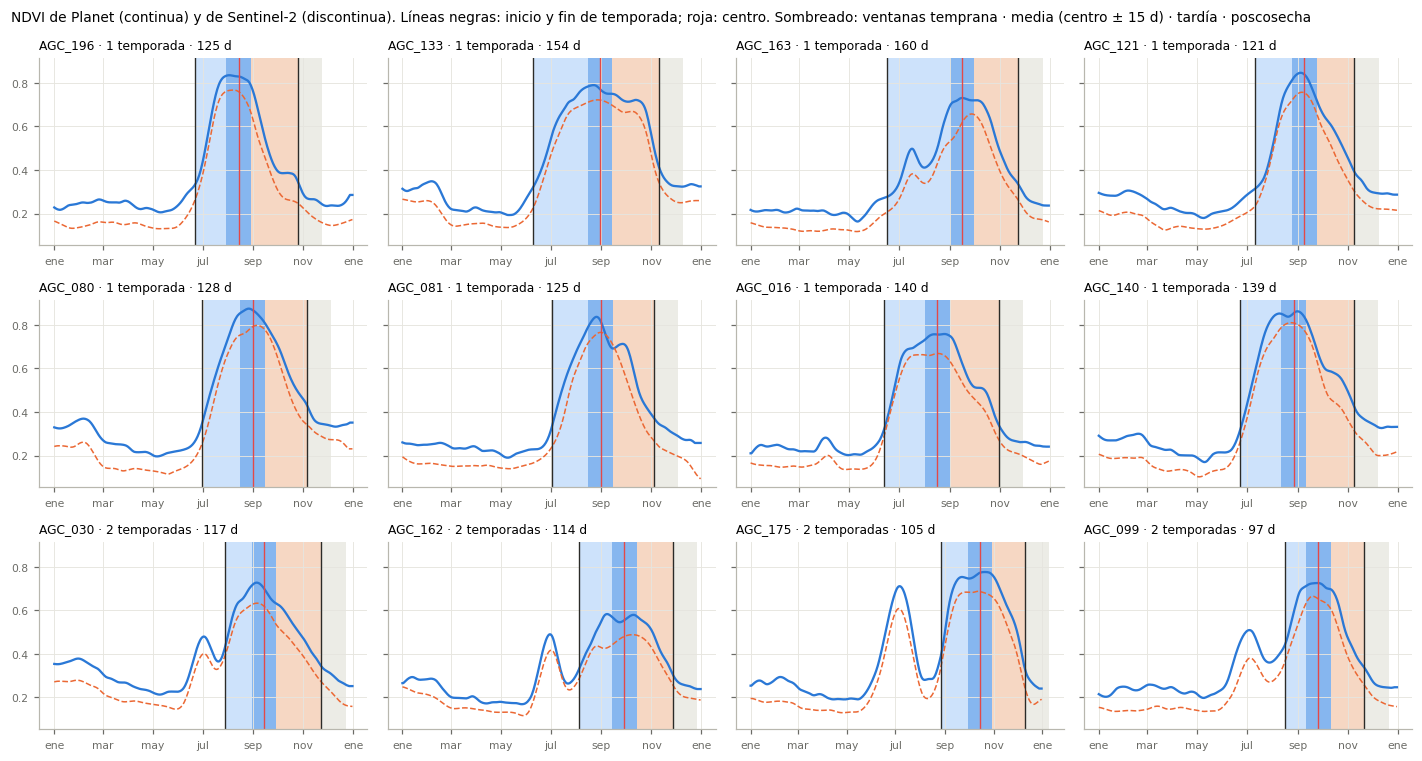

In [7]:
# 2.2 · Figura: parcelas de ejemplo con su temporada y sus ventanas de etapa
def stage_windows(r):
    return {"early": (r.sos, r.center - pd.Timedelta(days=MID_HALF)),
            "mid": (r.center - pd.Timedelta(days=MID_HALF), r.center + pd.Timedelta(days=MID_HALF)),
            "late": (r.center + pd.Timedelta(days=MID_HALF), r.eos),
            "post": (r.eos, r.eos + pd.Timedelta(days=POST_DAYS))}

two = pl.index[pl.n_seasons == 2].tolist()
one = pl.index[pl.n_seasons == 1].tolist()
ex = list(RNG.choice(one, min(8, len(one)), replace=False)) + list(RNG.choice(two, min(4, len(two)), replace=False))
fig, axes = plt.subplots(3, 4, figsize=(13, 7), sharey=True)
dp, ds = daily["Planet"], daily["Sentinel-2"]
for ax, pid in zip(axes.ravel(), ex):
    r = pl.loc[pid]
    g = dp[dp.ID_POLIGONO == pid]
    h = ds[(ds.ID_POLIGONO == pid) & (ds.date.dt.year == YEAR)]
    for name, (a, b) in stage_windows(r).items():
        ax.axvspan(a, b, color=STAGE_COLORS[name], zorder=0, lw=0)
    ax.plot(g.date, g.ndvi, color=COLORS["Planet"], lw=1.5)
    ax.plot(h.date, h.ndvi, color=COLORS["Sentinel-2"], lw=1.0, ls="--")
    for c, col in [("sos", INK), ("center", RED), ("eos", INK)]:
        ax.axvline(r[c], color=col, lw=0.9)
    ax.set_title(f"{pid} · {'2 temporadas' if r.n_seasons == 2 else '1 temporada'} · {r.los} d", fontsize=8, loc="left")
    ax.xaxis.set_major_formatter(FMT_MES)
    ax.tick_params(labelsize=7)
fig.suptitle("NDVI de Planet (continua) y de Sentinel-2 (discontinua). Líneas negras: inicio y fin de temporada; roja: centro. "
             "Sombreado: ventanas temprana · media (centro ± 15 d) · tardía · poscosecha", fontsize=9, x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "nb03_examples.png", bbox_inches="tight"); plt.show()

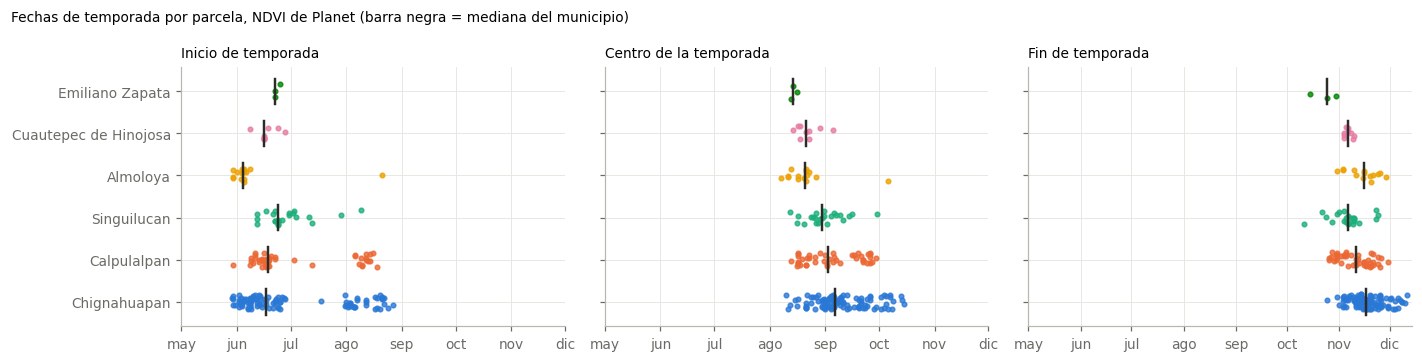

In [8]:
# 2.3 · Figura: calendario de la temporada por municipio
top = plots.Municipio.value_counts().index[:6].tolist()
t = pl.join(plots.set_index("ID_POLIGONO").Municipio)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, (c, label) in zip(axes, [("sos", "Inicio de temporada"), ("center", "Centro de la temporada"), ("eos", "Fin de temporada")]):
    for k, m in enumerate(top):
        v = t.loc[t.Municipio == m, c].dt.dayofyear.dropna()
        x = np.full(len(v), k) + RNG.uniform(-0.18, 0.18, len(v))
        ax.scatter(v, x, s=9, color=MUNI_COLORS[k], alpha=0.8)
        ax.plot([v.median()] * 2, [k - 0.3, k + 0.3], color=INK, lw=1.6)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top)
    ax.set_title(label, loc="left", fontsize=9)
    ticks = pd.date_range(f"{YEAR}-05-01", f"{YEAR}-12-01", freq="MS")
    ax.set_xticks(ticks.dayofyear)
    ax.set_xticklabels([MESES[m - 1] for m in ticks.month])
fig.suptitle("Fechas de temporada por parcela, NDVI de Planet (barra negra = mediana del municipio)", fontsize=9, x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "nb03_timing_by_municipality.png", bbox_inches="tight"); plt.show()

## 3 · Paso C: resumir cada índice en las etapas del propio cultivo

Con las fechas de Planet de cada parcela definimos estas ventanas (sombreadas en la figura anterior):

| Ventana | De → a | Etapa del cultivo que aproxima |
|---|---|---|
| `early` | SOS → centro − 15 d | emergencia, amacollamiento, encañe |
| `mid` | centro ± 15 d | espigamiento y floración, la etapa más sensible al estrés hídrico y térmico |
| `late` | centro + 15 d → EOS | llenado de grano y maduración |
| `season` | SOS → EOS | el ciclo completo |
| `post` | EOS → EOS + 30 d | después de la cosecha: residuo que queda en el campo (solo índices de residuo y labranza) |

Para cada sensor e índice calculamos la **media** en cada ventana y, para los índices de vegetación, el **máximo de la temporada**. Se usan las fechas de Planet para todos los sensores, así las ventanas son idénticas entre ellos. VI6T de Landsat solo se resume en `season` y `midlate` (de mitad de temporada a EOS) porque Landsat tiene pocas imágenes dentro de la temporada (mediana de 13).

Las **variables fenológicas de la forma de la curva** (paso A) se añaden con el prefijo `pl_ndvi_` (Planet) y `s2_ndvi_` (Sentinel-2): fechas como día del año, duraciones en días, tasas en NDVI/día e integrales en NDVI·día.

In [9]:
# 3.1 · Variables fenológicas
FEAT = pd.DataFrame(index=pd.Index(IDS, name="ID_POLIGONO"))
PHENO_COLS = {"sos": ("inicio de temporada (20 % de la amplitud)", "day of year"), "sos50": ("punto medio del reverdecimiento (50 % de la amplitud)", "day of year"),
              "pos": ("fecha del pico", "day of year"), "center": ("centro de la temporada (mitad del área verde)", "day of year"),
              "eos50": ("punto medio de la senescencia (50 % de la amplitud)", "day of year"), "eos": ("fin de temporada (20 % de la amplitud)", "day of year"),
              "los": ("duración de la temporada SOS→EOS", "days"), "los50": ("duración de la temporada al 50 % de la amplitud", "days"),
              "peak": ("valor del pico", "NDVI"), "amplitude": ("pico − nivel de suelo desnudo", "NDVI"),
              "base_left": ("nivel de suelo desnudo antes de la temporada", "NDVI"), "base_right": ("nivel después de la temporada", "NDVI"),
              "greenup_rate": ("reverdecimiento más rápido", "NDVI/day"), "senescence_rate": ("senescencia más rápida", "NDVI/day"),
              "integral_season": ("área verde SOS→EOS sobre el suelo desnudo", "NDVI·day"), "integral_veg": ("área verde SOS→pico", "NDVI·day"),
              "integral_grainfill": ("área verde pico→EOS", "NDVI·day"), "plateau_days": ("días a menos de 10 % del pico", "days"),
              "n_seasons": ("número de temporadas abr–dic (2 = rebrote temprano + principal)", "count"),
              "early_flush": ("un reverdecimiento previo y separado antes de la temporada principal", "0/1"),
              "early_flush_amp": ("altura del rebrote temprano sobre su nivel de suelo desnudo (0 si no hay)", "NDVI"),
              "early_flush_area": ("área verde del rebrote temprano (0 si no hay)", "NDVI·day")}
for s, prefix in [("Planet", "pl_ndvi"), ("Sentinel-2", "s2_ndvi")]:
    t = PH[s]
    for c, (desc, unit) in PHENO_COLS.items():
        v = t[c].dt.dayofyear if c in ("sos", "sos50", "pos", "center", "eos50", "eos") else t[c]
        FEAT[f"{prefix}_{c}"] = pd.to_numeric(v, errors="coerce").astype(float)
        register(f"{prefix}_{c}", "phenology", s, "ndvi", "season", c, desc, unit)
for s, prefix in [("Planet", "pl"), ("Sentinel-2", "s2")]:
    FEAT[f"{prefix}_season_images"] = SUPPORT[s].n_images.astype(float)
    FEAT[f"{prefix}_season_max_gap"] = SUPPORT[s].max_gap_days.astype(float)
    FEAT[f"{prefix}_low_confidence"] = (SUPPORT[s].max_gap_days > MAX_GAP_OK[s]).astype(float)
    register(f"{prefix}_season_images", "quality", s, "-", "season", "count", "imágenes conservadas dentro de la temporada de la parcela", "count")
    register(f"{prefix}_season_max_gap", "quality", s, "-", "season", "max", "tramo más largo sin imagen conservada en la temporada", "days")
    register(f"{prefix}_low_confidence", "quality", s, "-", "season", "flag", f"hueco más largo > {MAX_GAP_OK[s]} d", "0/1")
print(FEAT.shape)

(197, 50)


In [10]:
# 3.2 · Resúmenes por ventana de cada índice (fechas de la fenología del NDVI de Planet)
dates = pl[["sos", "center", "eos"]].copy()
dates["mid_a"] = dates.center - pd.Timedelta(days=MID_HALF)
dates["mid_b"] = dates.center + pd.Timedelta(days=MID_HALF)
dates["post_b"] = dates.eos + pd.Timedelta(days=POST_DAYS)
WINDOWS = {"early": ("sos", "mid_a"), "mid": ("mid_a", "mid_b"), "late": ("mid_b", "eos"),
           "season": ("sos", "eos"), "post": ("eos", "post_b"), "midlate": ("mid_a", "eos")}
VEG = {"ndvi", "evi", "lai", "msavi", "savi", "fapar"}

def window_features(sensor, prefix, windows, indices, add_max=True):
    d = daily[sensor]
    d = d[d.date.dt.year == YEAR].merge(dates.reset_index(), on="ID_POLIGONO", how="inner")
    out = {}
    for w, (a, b) in windows.items():
        m = (d.date >= d[a]) & (d.date <= d[b])
        g = d[m].groupby("ID_POLIGONO")[indices].mean().reindex(IDS)
        for i in indices:
            out[f"{prefix}_{i}_{w}_mean"] = g[i]
            register(f"{prefix}_{i}_{w}_mean", "window", sensor, i, w, "mean", f"media diaria de {i.upper()} en la ventana {w}")
    if add_max:
        m = (d.date >= d.sos) & (d.date <= d.eos)
        g = d[m].groupby("ID_POLIGONO")[[i for i in indices if i in VEG]].max().reindex(IDS)
        for i in g.columns:
            out[f"{prefix}_{i}_season_max"] = g[i]
            register(f"{prefix}_{i}_season_max", "window", sensor, i, "season", "max", f"máximo de la temporada de {i.upper()} diario")
    return pd.DataFrame(out)

core = {k: WINDOWS[k] for k in ["early", "mid", "late", "season"]}
pl_idx = [i for i in INDICES["Planet"] if i != "ndvi"]          # la forma del NDVI de Planet ya está en las variables fenológicas
s2_idx = INDICES["Sentinel-2"]
parts = [window_features("Planet", "pl", core, pl_idx),
         window_features("Sentinel-2", "s2", core, s2_idx),
         window_features("Sentinel-2", "s2", {"post": WINDOWS["post"]}, [i for i in RESIDUE_IDX if i in s2_idx], add_max=False),
         window_features("Landsat", "ls", {"season": WINDOWS["season"], "midlate": WINDOWS["midlate"]}, INDICES["Landsat"], add_max=False)]
FEAT = pd.concat([FEAT] + parts, axis=1)

ls_kept = kept[kept.sensor == "Landsat"].merge(dates[["mid_a", "eos"]].reset_index(), on="ID_POLIGONO")
n_ls = ls_kept[(ls_kept.date >= ls_kept.mid_a) & (ls_kept.date <= ls_kept.eos)].groupby("ID_POLIGONO").size().reindex(IDS, fill_value=0)
FEAT["ls_midlate_images"] = n_ls.astype(float)
FEAT["ls_low_confidence"] = (n_ls < 3).astype(float)
register("ls_midlate_images", "quality", "Landsat", "-", "midlate", "count", "imágenes de Landsat conservadas de mitad de temporada a EOS", "count")
register("ls_low_confidence", "quality", "Landsat", "-", "midlate", "flag", "menos de 3 imágenes de Landsat de mitad de temporada a EOS", "0/1")
check("Landsat: imágenes disponibles de mitad de temporada a EOS", True,
      f"mediana {n_ls.median():.0f}; {int((n_ls < 3).sum())} parcelas con < 3 imágenes marcadas ls_low_confidence", info=True)
print(FEAT.shape)

[INFO] Landsat: imágenes disponibles de mitad de temporada a EOS — mediana 6; 5 parcelas con < 3 imágenes marcadas ls_low_confidence
(197, 167)


## 4 · Paso D: ¿qué tan uniforme es el cultivo dentro de cada parcela?

Cada imagen de Planet trae los estadísticos **espaciales** del NDVI entre los píxeles de la parcela (media, desviación estándar, mínimo y máximo; los píxeles de Planet miden ~3 m). Un campo con emergencia dispareja, esquinas encharcadas o franjas con maleza tiene mucha dispersión a mitad de temporada aunque su promedio se vea bien, y la falta de uniformidad suele costar rendimiento.

De las imágenes de Planet conservadas a ± 20 días del centro de la temporada de cada parcela tomamos la mediana de:
- `cv` = desviación estándar ÷ media (dispersión relativa);
- `std` = desviación estándar;
- `low_patch` = media − mínimo (cuánto se rezaga la peor parte respecto al promedio);
- `range` = máximo − mínimo.

*Precaución al interpretar:* las parcelas pequeñas tienen proporcionalmente más píxeles de borde (mezclados con caminos o linderos), lo que infla la dispersión. El área de la parcela se conserva como variable aparte para que el modelo pueda separar ambos efectos.

In [11]:
# 4.1 · Variables de uniformidad (Planet, alrededor de la mitad de temporada)
u = qc[(qc.sensor == "Planet") & (qc.status == "ok")].merge(dates[["center"]].reset_index(), on="ID_POLIGONO")
u = u[(u.date - u.center).dt.days.abs() <= UNIF_HALF]
u = u.assign(cv=u.ndvi_std / u.ndvi_promedio, std=u.ndvi_std,
             low_patch=u.ndvi_promedio - u.ndvi_min, range=u.ndvi_max - u.ndvi_min)
g = u.groupby("ID_POLIGONO")[["cv", "std", "low_patch", "range"]].median().reindex(IDS)
n_u = u.groupby("ID_POLIGONO").size().reindex(IDS, fill_value=0)
for c, desc in [("cv", "coeficiente de variación espacial del NDVI"), ("std", "DE espacial del NDVI"),
                ("low_patch", "NDVI medio − mínimo (zonas rezagadas)"), ("range", "NDVI máximo − mínimo")]:
    FEAT[f"pl_unif_ndvi_{c}"] = g[c]
    register(f"pl_unif_ndvi_{c}", "uniformity", "Planet", "ndvi", "centre ± 20 d", "median", desc)
FEAT["pl_unif_images"] = n_u.astype(float)
register("pl_unif_images", "quality", "Planet", "-", "centre ± 20 d", "count", "imágenes de Planet usadas para la uniformidad", "count")
FEAT["area_ha"] = plots.set_index("ID_POLIGONO").AREA_HA.reindex(IDS).astype(float)
register("area_ha", "plot", "-", "-", "-", "-", "área de la parcela", "ha")
display(g.describe().round(3).T)
r = np.corrcoef(np.log(FEAT.area_ha), FEAT.pl_unif_ndvi_cv.fillna(FEAT.pl_unif_ndvi_cv.median()))[0, 1]
check("Uniformidad: imágenes disponibles alrededor de la mitad de temporada", bool((n_u >= 3).all()),
      f"mediana {n_u.median():.0f} imágenes; correlación del CV espacial con log(área) = {r:+.2f} (efecto de borde)")

           count   mean    std    min    25%    50%    75%    max
cv         197.0  0.096  0.045  0.041  0.064  0.088  0.110  0.335
std        197.0  0.066  0.025  0.029  0.049  0.062  0.074  0.183
low_patch  197.0  0.264  0.091  0.087  0.204  0.247  0.308  0.642
range      197.0  0.396  0.113  0.176  0.316  0.378  0.448  0.881
[PASS] Uniformidad: imágenes disponibles alrededor de la mitad de temporada — mediana 15 imágenes; correlación del CV espacial con log(área) = -0.05 (efecto de borde)


## 5 · Paso E: el historial de la parcela (2022–2024) y cómo se compara 2025

El rendimiento también depende del terreno mismo: profundidad del suelo, drenaje y cómo lo maneja el productor. Eso no cambia de un año a otro, así que una parcela que estuvo más verde que sus vecinas en 2022–2024 probablemente es una mejor parcela. Sentinel-2 cubre 2022–2025, así que para cada parcela y cada año anterior aplicamos la misma detección de temporada (paso A) y registramos el NDVI máximo, el área verde y el centro de la temporada. Luego:

- `hist_*_mean`: el pico, el área verde y el calendario habituales de la parcela;
- `hist_peak_cv`: qué tan estable es de un año a otro;
- `hist_n_crop_seasons`: en cuántos de los tres años se vio una temporada de cultivo clara (amplitud ≥ 0.20); aquí aparecen los años de descanso o pastizal;
- `anom_*_2025`: 2025 menos el historial propio de la parcela: ¿fue un año mejor o peor *para esta parcela*?

Todas las variables de historial usan solo Sentinel-2, así que 2025 se compara con el mismo instrumento.

In [12]:
# 5.1 · Variables de historial con Sentinel-2
hist = []
for y in [2022, 2023, 2024, 2025]:
    t = season_table("Sentinel-2", win=(f"{y}-04-01", f"{y}-12-31"))
    hist.append(pd.DataFrame({"year": y, "peak": t.peak, "integral": t.integral_season, "amplitude": t.amplitude,
                              "center": t.center.dt.dayofyear, "found": t.season_found.astype(bool)}))
H = pd.concat(hist).reset_index()
H.loc[~H.found | (H.amplitude < 0.20), ["peak", "integral", "center"]] = np.nan
past = H[H.year < 2025].groupby("ID_POLIGONO")
now = H[H.year == 2025].set_index("ID_POLIGONO")
hist_feats = pd.DataFrame({
    "hist_s2_peak_mean": past.peak.mean(), "hist_s2_peak_cv": past.peak.std() / past.peak.mean(),
    "hist_s2_integral_mean": past.integral.mean(), "hist_s2_center_mean": past.center.mean(),
    "hist_s2_n_crop_seasons": past.peak.count().astype(float)}).reindex(IDS)
hist_feats["anom_s2_peak_2025"] = now.peak.reindex(IDS) - hist_feats.hist_s2_peak_mean
hist_feats["anom_s2_integral_2025"] = now.integral.reindex(IDS) - hist_feats.hist_s2_integral_mean
hist_feats["anom_s2_center_2025"] = now.center.reindex(IDS) - hist_feats.hist_s2_center_mean
desc = {"hist_s2_peak_mean": ("NDVI máximo medio de las temporadas 2022–2024", "NDVI"),
        "hist_s2_peak_cv": ("CV interanual del NDVI máximo 2022–2024", "ratio"),
        "hist_s2_integral_mean": ("área verde media de la temporada 2022–2024", "NDVI·day"),
        "hist_s2_center_mean": ("centro medio de la temporada 2022–2024", "day of year"),
        "hist_s2_n_crop_seasons": ("años 2022–2024 con una temporada de cultivo clara (amplitud ≥ 0.20)", "count"),
        "anom_s2_peak_2025": ("pico 2025 menos la media 2022–2024 de la parcela", "NDVI"),
        "anom_s2_integral_2025": ("área verde 2025 menos la media 2022–2024 de la parcela", "NDVI·day"),
        "anom_s2_center_2025": ("centro de la temporada 2025 menos la media 2022–2024 de la parcela (+ = más tarde)", "days")}
for c, (dsc, unit) in desc.items():
    FEAT[c] = hist_feats[c]
    register(c, "history", "Sentinel-2", "ndvi", "2022–2024", c.split("_")[-1], dsc, unit)
display(H.groupby("year")[["peak", "integral", "center"]].median().round(2))
display(hist_feats.hist_s2_n_crop_seasons.value_counts().sort_index().rename("plots").to_frame())
check("Historial: temporadas de cultivo detectadas en 2022–2024", True,
      f"parcelas con temporada de cultivo en los 3 años: {int((hist_feats.hist_s2_n_crop_seasons == 3).sum())}; "
      f"en ninguno: {int((hist_feats.hist_s2_n_crop_seasons == 0).sum())}", info=True)

      peak  integral  center
year                        
2022  0.62     41.41   242.0
2023  0.53     27.40   226.5
2024  0.68     50.61   250.0
2025  0.66     48.08   245.0
                        plots
hist_s2_n_crop_seasons       
1.0                         3
2.0                        11
3.0                       183
[INFO] Historial: temporadas de cultivo detectadas en 2022–2024 — parcelas con temporada de cultivo en los 3 años: 183; en ninguno: 0


## 6 · Paso F: integrar, depurar y documentar

- Las **variables constantes o casi constantes** (un mismo valor en ≥ 95 % de las parcelas) no aportan información y se eliminan.
- Los **valores faltantes** se reportan por variable. *No* se rellenan aquí: rellenar usa estadísticas de los datos, así que debe hacerse dentro de cada pliegue de validación cruzada (cuadernos 06 y 07) para no filtrar información de las parcelas apartadas.
- Cada variable que queda se lista en `feature_catalog.csv` (grupo, sensor, índice, ventana, estadístico, unidad y descripción).
- Las **variables de calidad** (conteo de imágenes, huecos más largos, marcas de baja confianza) describen los *datos*, no el cultivo. En una exploración, el número de imágenes de Planet se correlacionaba con el rendimiento (ρ ≈ −0.2) solo porque los lugares más nublados reciben menos imágenes: una señal espuria. Se conservan para diagnóstico, pero se marcan con `use_in_model = False` en el catálogo.

In [13]:
# 6.1 · Depuración, catálogo y guardado
assert FEAT.index.is_unique and len(FEAT) == len(IDS)
assert not any("rendimiento" in c.lower() for c in FEAT.columns), "el rendimiento nunca debe ser una variable"
top_share = FEAT.apply(lambda c: c.value_counts(normalize=True, dropna=True).iloc[0] if c.notna().any() else 1.0)
constant = top_share[top_share >= 0.95].index.tolist()
keep_anyway = {"pl_low_confidence", "s2_low_confidence", "ls_low_confidence"}     # las marcas poco frecuentes deben serlo
dropped = [c for c in constant if c not in keep_anyway]
FEAT = FEAT.drop(columns=dropped)
cat = pd.DataFrame(CATALOG).drop_duplicates("feature").set_index("feature")
cat["kept"] = cat.index.isin(FEAT.columns)
# las variables de calidad (conteos de imágenes, huecos, marcas) describen los DATOS, no el cultivo: se conservan para
# diagnóstico y para ponderar parcelas inciertas, pero no se ofrecen a los modelos como predictores
cat["use_in_model"] = cat.kept & (cat.group != "quality")
cat["missing_%"] = (100 * FEAT.isna().mean()).reindex(cat.index).round(2)
cat.to_csv(FEATURES / "feature_catalog.csv")

miss = FEAT.isna().mean()
heavy = miss[miss > 0.05]
check("Variables: una fila por parcela, identificadores únicos", True, f"{FEAT.shape[0]} parcelas × {FEAT.shape[1]} variables", info=True)
check("Variables: ≤ 5 % de faltantes por variable", heavy.empty,
      ", ".join(f"{k} {100 * v:.0f} %" for k, v in heavy.sort_values(ascending=False).head(10).items()) if len(heavy)
      else f"máximo {100 * miss.max():.1f} %")
check("Variables: constantes eliminadas", True, f"{len(dropped)} eliminadas: {dropped[:10]}", info=True)
display(cat[cat.kept].groupby(["group", "sensor"]).size().rename("features").to_frame())

FEAT = FEAT.copy()
FEAT.reset_index().to_parquet(FEATURES / "sat_features.parquet", index=False)
pheno_dates = pl[["sos", "sos50", "pos", "center", "eos50", "eos", "los", "n_seasons"]].copy()
pheno_dates["mid_start"], pheno_dates["mid_end"] = dates.mid_a, dates.mid_b
pheno_dates.reset_index().to_parquet(FEATURES / "phenology_dates.parquet", index=False)
print("guardado:", FEATURES / "sat_features.parquet", "y phenology_dates.parquet")

[INFO] Variables: una fila por parcela, identificadores únicos — 197 parcelas × 181 variables
[PASS] Variables: ≤ 5 % de faltantes por variable — máximo 1.5 %
[INFO] Variables: constantes eliminadas — 0 eliminadas: []
                       features
group      sensor              
history    Sentinel-2         8
phenology  Planet            22
           Sentinel-2        22
plot       -                  1
quality    Landsat            2
           Planet             4
           Sentinel-2         3
uniformity Planet             4
window     Landsat            2
           Planet            15
           Sentinel-2        98
guardado: /content/drive/MyDrive/AgroCebada/features/sat_features.parquet y phenology_dates.parquet


## 7 · Una primera mirada, puramente descriptiva, al rendimiento (solo parcelas de entrenamiento)

**Esta celda no selecciona nada.** Solo muestra si las variables tienen señal, para orientar las expectativas. La selección de variables ocurre después, *dentro* de los pliegues de validación cruzada, así que las parcelas apartadas nunca se usan para elegir variables.

Dos vistas de la correlación de rangos de Spearman con el rendimiento:
- **global**: refleja sobre todo diferencias *entre* municipios (ubicación), que la referencia de ubicación ya captura (RMSE ≈ 0.50 t/ha);
- **dentro de municipio**: la variable y el rendimiento se centran en la media de su municipio antes de correlacionar. Es la señal que el modelo necesita para superar a la referencia de ubicación: por qué una parcela rinde más que sus vecinas.

Con 138 parcelas, |ρ| ≈ 0.17 es aproximadamente el umbral de significancia estadística (p ≈ 0.05), así que se esperan valores modestos.

                            overall  within_municipality      group      sensor
s2_ndvi_integral_grainfill   -0.073               -0.265  phenology  Sentinel-2
s2_ndvi_pos                   0.148                0.255  phenology  Sentinel-2
pl_ndvi_base_left             0.335                0.254  phenology      Planet
s2_ndvi_base_left             0.358                0.239  phenology  Sentinel-2
s2_ndvi_center                0.138                0.234  phenology  Sentinel-2
s2_ndvi_sos50                -0.120                0.224  phenology  Sentinel-2
pl_ndvi_center                0.147                0.223  phenology      Planet
s2_ndvi_los50                 0.327               -0.211  phenology  Sentinel-2
pl_ndvi_pos                   0.200                0.208  phenology      Planet
pl_ndvi_sos50                -0.114                0.203  phenology      Planet
s2_ndvi_integral_season       0.028               -0.201  phenology  Sentinel-2
anom_s2_integral_2025         0.024     

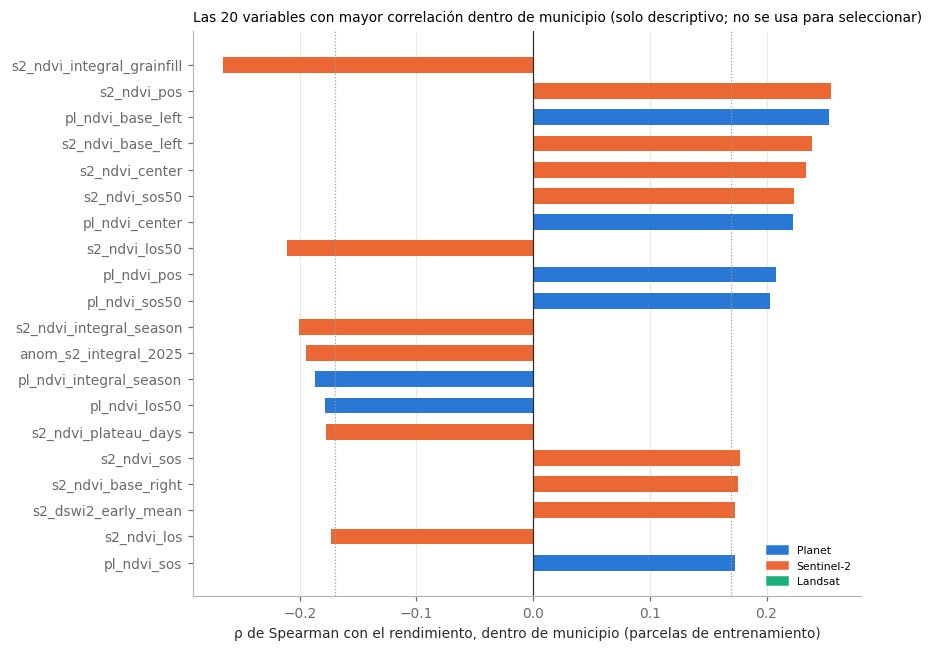

[INFO] Descriptivo: variables con |ρ| ≥ 0.17 dentro de municipio — 21 de 168; la más fuerte: s2_ndvi_integral_grainfill (ρ = -0.27)


In [14]:
# 7.1 · Correlaciones descriptivas (solo parcelas de entrenamiento)
lab = pd.read_parquet(INTERIM / "labels.parquet").set_index("ID_POLIGONO")
tr = FEAT.join(lab[["RENDIMIENTO_T_HA", "is_train"]]).join(plots.set_index("ID_POLIGONO").Municipio)
tr = tr[tr.is_train]
num = [c for c in FEAT.columns if FEAT[c].nunique() > 2 and cat.loc[c, "use_in_model"]]
overall = tr[num].corrwith(tr.RENDIMIENTO_T_HA, method="spearman")
dm = tr[num + ["RENDIMIENTO_T_HA"]].sub(tr.groupby("Municipio")[num + ["RENDIMIENTO_T_HA"]].transform("mean"))
within = dm[num].corrwith(dm.RENDIMIENTO_T_HA, method="spearman")
look = pd.DataFrame({"overall": overall, "within_municipality": within}).join(cat[["group", "sensor"]])
look = look.reindex(look.within_municipality.abs().sort_values(ascending=False).index)
look.to_csv(QA / "nb03_descriptive_correlations.csv")
display(look.head(20).round(3))

t20 = look.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
cols = [COLORS.get(s, GREY) for s in t20.sensor]
ax.barh(t20.index, t20.within_municipality, color=cols, height=0.6)
ax.axvline(0, color=INK, lw=0.8)
for x in (-0.17, 0.17):
    ax.axvline(x, color=GREY, lw=0.8, ls=":")
ax.grid(axis="y", visible=False)
ax.set_xlabel("ρ de Spearman con el rendimiento, dentro de municipio (parcelas de entrenamiento)")
ax.set_title("Las 20 variables con mayor correlación dentro de municipio (solo descriptivo; no se usa para seleccionar)",
             loc="left", fontsize=9)
handles = [matplotlib.patches.Patch(color=c, label=s) for s, c in COLORS.items()]
ax.legend(handles=handles, fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "nb03_descriptive_correlations.png", bbox_inches="tight"); plt.show()
n_sig = int((look.within_municipality.abs() >= 0.17).sum())
check("Descriptivo: variables con |ρ| ≥ 0.17 dentro de municipio", True,
      f"{n_sig} de {len(look)}; la más fuerte: {look.index[0]} (ρ = {look.within_municipality.iloc[0]:+.2f})", info=True)

In [15]:
# 7.2 · Reporte
def md_table(df):
    df = df.copy()
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join("" if pd.isna(v) else (f"{v:.4g}" if isinstance(v, float) else str(v)) for v in r.values) + " |")
    return "\n".join(out)

chk = pd.DataFrame(CHECKS)
dd = pl[["sos", "pos", "center", "eos"]].apply(lambda c: c.dt.dayofyear)
dd["los"] = pl.los
lines = ["# Reporte del cuaderno 03: fenología y variables satelitales",
         f"Generado {datetime.now():%Y-%m-%d %H:%M} · Colab: {IN_COLAB}", "",
         f"**Conteo de estados:** {chk.status.value_counts().to_dict()}", "",
         "## Verificaciones", md_table(chk), "",
         "## Fechas de temporada de Planet (día del año 2025)", md_table(dd.describe().round(0).T.reset_index()), "",
         "## Diferencias de fechas Planet frente a Sentinel-2 (días, S2 − Planet)", md_table(agree.describe().round(1).T.reset_index()), "",
         "## Calendario de la temporada por municipio (Planet, día del año mediano)",
         md_table(pl.join(plots.set_index("ID_POLIGONO").Municipio).assign(
             sos=lambda x: x.sos.dt.dayofyear, center=lambda x: x.center.dt.dayofyear, eos=lambda x: x.eos.dt.dayofyear)
             .groupby("Municipio")[["sos", "center", "eos", "los", "peak", "n_seasons"]].median().round(2).reset_index()), "",
         "## Variables por grupo", md_table(cat[cat.kept].groupby(["group", "sensor"]).size().rename("n").reset_index()), "",
         "## Correlaciones descriptivas con el rendimiento (parcelas de entrenamiento; 25 primeras por |ρ| dentro de municipio)",
         md_table(look.head(25).round(3).reset_index().rename(columns={"index": "feature"}))]
(QA / "nb03_report.md").write_text("\n".join(lines), encoding="utf-8")
print(chk.status.value_counts().to_dict())
problems = chk[chk.status.isin(["WARN", "FAIL"])]
display(problems if len(problems) else "Todas las verificaciones pasaron.")
print(f"Reporte: {QA / 'nb03_report.md'}")

{'PASS': 7, 'INFO': 5}
Todas las verificaciones pasaron.
Reporte: /content/drive/MyDrive/AgroCebada/qa/nb03_report.md
